# Paired spectra

> Compare Bruker and Thermo spectra of the same soils, and test the OSSL models on both instruments

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspectfm.preprocessing import SNV
from soilspecdl.all import predict
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run. Which Bruker instrument and accessory measured these soils, and whether the Bruker set is valid to use, are still open questions for the Fukushima data team.

## Data

The soils with both Bruker and Thermo spectra, except those in `excluded`. The Bruker files end at 3997.5 cm⁻¹, so the grid stops at 3996 cm⁻¹. Both spectra of a soil are averaged over their replicates and interpolated onto the same grid:

In [ ]:
#| fukudata
pw = np.arange(650, 3997, 2)
ids = [i for i in sorted(set(bruker_files()) & set(spa_files()), key=int) if i not in excluded]
br, th = load_bruker(pw, ids), load_fuku(pw, ids)
test_eq(br.sample_ids, th.sample_ids)
len(ids), sum(int(i) >= 2600 for i in ids)

(376, 316)

In [ ]:
#| fukudata
gas_bands = {'H₂O': [(1300, 2000), (3500, 3950)], 'CO₂': [(650, 720), (2280, 2390)]}
def shade(ax):
    for (gas, bands), color in zip(gas_bands.items(), ['tab:blue', 'tab:gray']):
        for lo, hi in bands: ax.axvspan(lo, hi, color=color, alpha=0.1, lw=0)
    ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)')
in_band = lambda lo, hi: (pw >= lo) & (pw <= hi)
regions = {'650–1300': in_band(650, 1300), 'H₂O 1300–2000': in_band(1300, 2000), 'CO₂ 2280–2390': in_band(2280, 2390), 'quiet 2400–2800': in_band(2400, 2800), '2800–3500': in_band(2800, 3500), 'H₂O 3500–3950': in_band(3500, 3950)}

## Mean spectra

The mean raw and SNV spectra of each instrument, and the difference of the SNV means. The shaded regions are the water vapour (blue) and CO₂ (grey) bands:

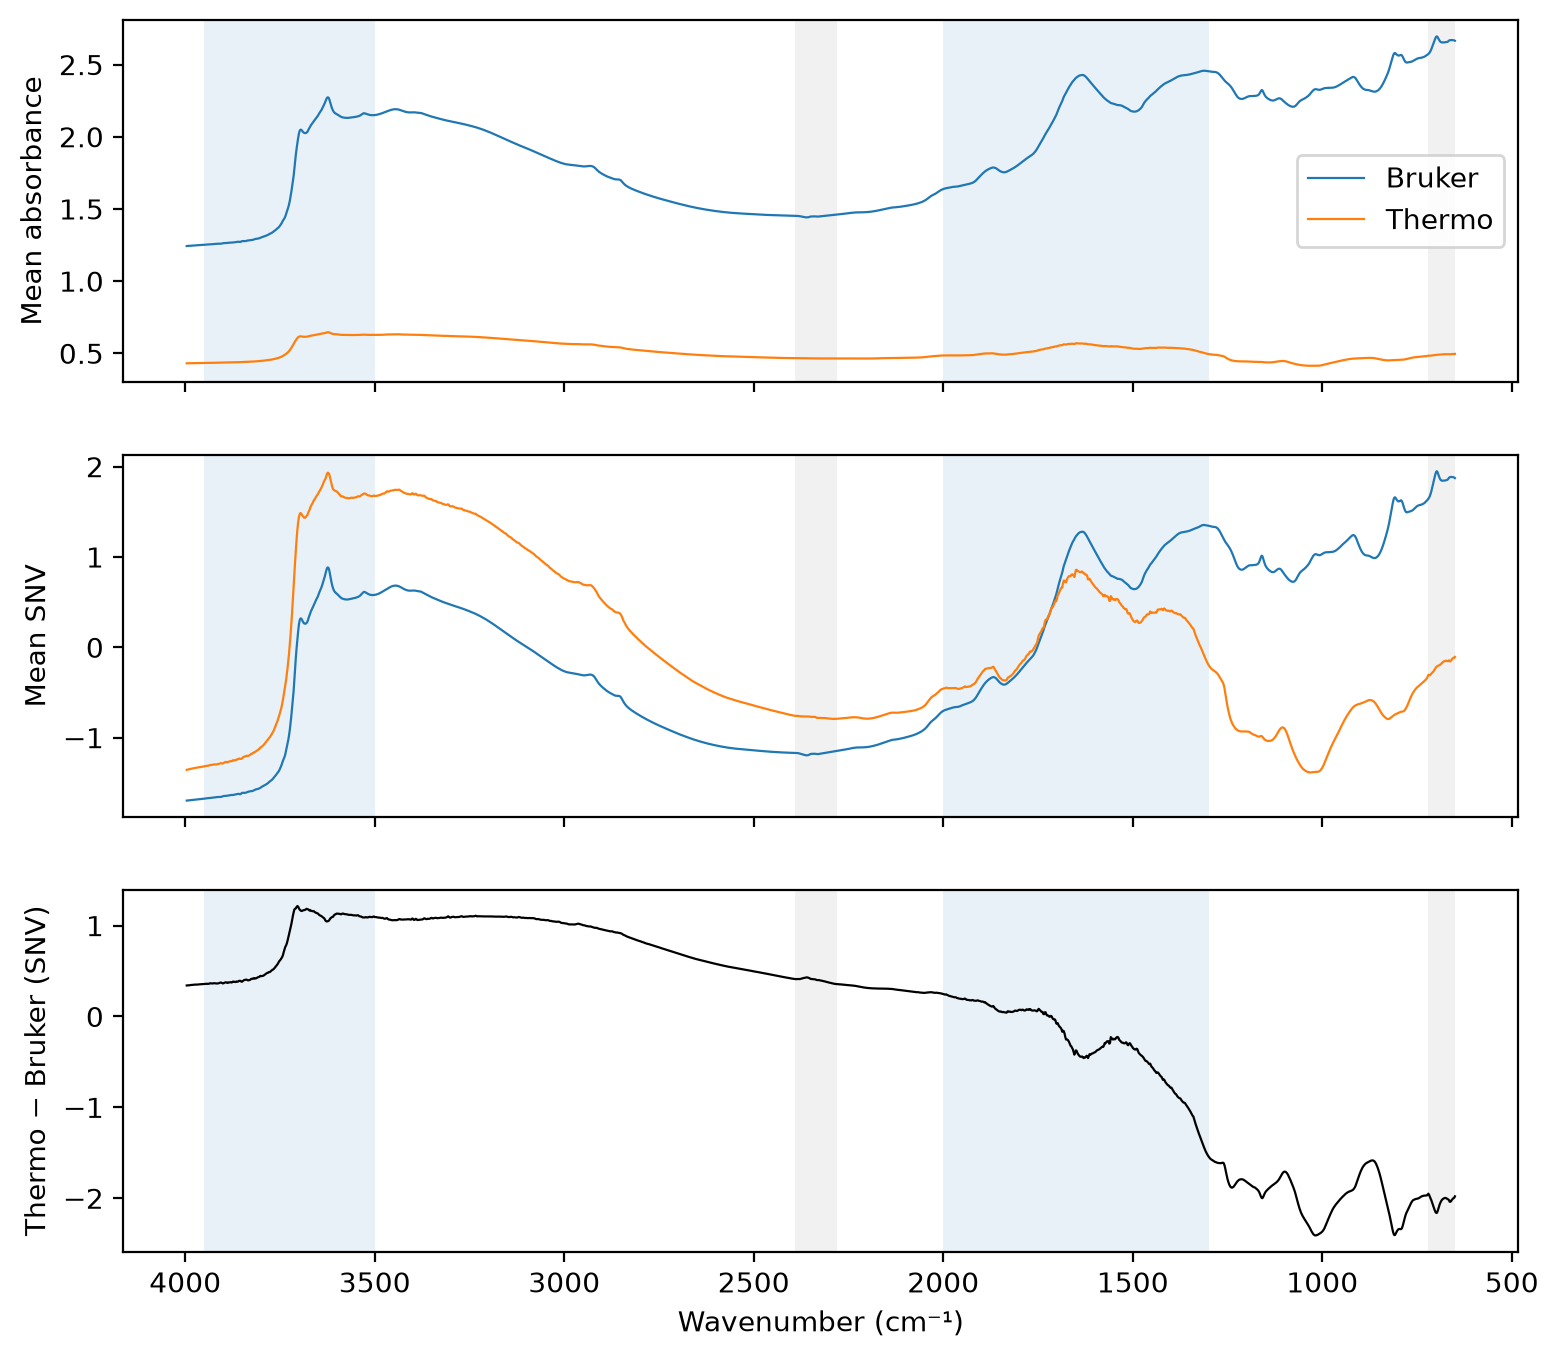

{'Bruker': (1.918, 0.398), 'Thermo': (0.514, 0.066)}

In [ ]:
#| fukudata
snv = SNV()
S = {'Bruker': br.spectra, 'Thermo': th.spectra}
fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for k, X in S.items():
    axs[0].plot(pw, X.mean(0), lw=0.8, label=k)
    axs[1].plot(pw, snv.transform(X).mean(0), lw=0.8, label=k)
axs[2].plot(pw, snv.transform(th.spectra).mean(0) - snv.transform(br.spectra).mean(0), lw=0.8, c='k')
for ax, t in zip(axs, ['Mean absorbance', 'Mean SNV', 'Thermo − Bruker (SNV)']): ax.set_ylabel(t); shade(ax)
axs[0].legend()
for ax in axs[:2]: ax.set_xlabel('')
{k: (round(float(X.mean()), 3), round(float(X.std(1).mean()), 3)) for k, X in S.items()}

The pair of numbers per instrument is the mean absorbance and the mean within-spectrum standard deviation.

## Agreement

For each soil, the correlation between its Bruker and Thermo spectra, as median and 5th percentile over the soils, for raw spectra, SNV and SNV with the first derivative:

In [ ]:
#| fukudata
pre = {'raw': None, 'SNV': Pipeline([('snv', SNV())]), 'SNV + d1': preprocessings()['snv_d1']}
tf = lambda p, X: X if p is None else p.fit_transform(X)
T = {k: (tf(p, br.spectra), tf(p, th.spectra)) for k, p in pre.items()}
pd.DataFrame({k: (lambda r: {'median': np.median(r), '5%': np.quantile(r, 0.05)})([np.corrcoef(a, b)[0, 1] for a, b in zip(*v)]) for k, v in T.items()}).T.round(3)

,median,5%
raw,0.273,0.124
SNV,0.273,0.124
SNV + d1,0.776,0.681


Across soils, at each wavenumber: does the Thermo value rise where the Bruker value rises? The correlation between instruments over the soils, at each wavenumber, and its mean by region:

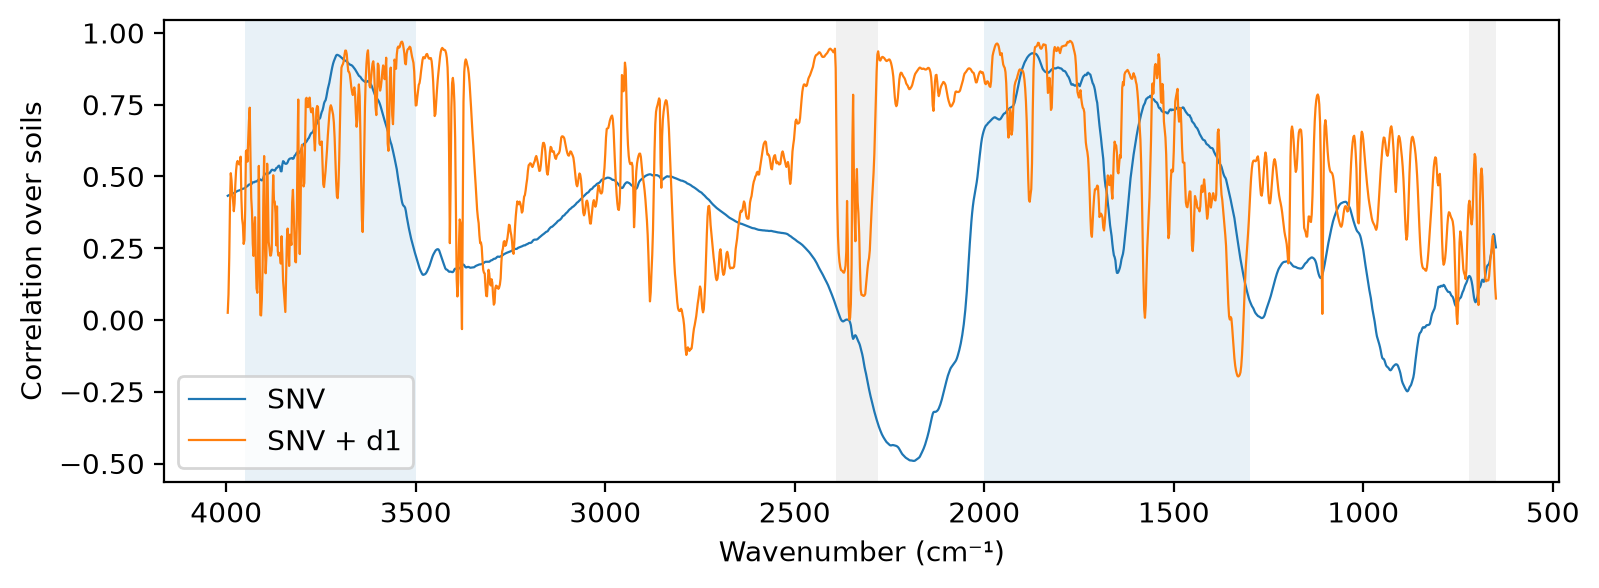

,SNV,SNV + d1
650–1300,0.10,0.43
H₂O 1300–2000,0.66,0.61
CO₂ 2280–2390,-0.11,0.32
quiet 2400–2800,0.32,0.45
2800–3500,0.34,0.52
H₂O 3500–3950,0.64,0.62


In [ ]:
#| fukudata
def colcorr(A, B):
    A, B = A - A.mean(0), B - B.mean(0)
    return (A * B).sum(0) / np.sqrt((A**2).sum(0) * (B**2).sum(0))
cc = {k: colcorr(*T[k]) for k in ['SNV', 'SNV + d1']}
fig, ax = plt.subplots(figsize=(9, 3))
for k, c in cc.items(): ax.plot(pw, c, lw=0.8, label=k)
ax.set_ylabel('Correlation over soils'); ax.legend(); shade(ax)
pd.DataFrame({k: {n: c[m].mean() for n, m in regions.items()} for k, c in cc.items()}).round(2)

## Shift and broadening

A wavenumber calibration offset between the instruments shifts every band. The cross-correlation of the mean SNV + d1 spectra, on a 0.1 cm⁻¹ grid, peaks at the shift that best aligns the Thermo spectrum with the Bruker one:

In [ ]:
#| fukudata
fine = np.arange(pw[0] + 20, pw[-1] - 20, 0.1)
mb, mt = (np.interp(fine, pw, T['SNV + d1'][i].mean(0)) for i in (0, 1))
lags = np.arange(-50, 51)
n = len(fine)
xc = [np.corrcoef(mb[50:n-50], mt[50+l:n-50+l])[0, 1] for l in lags]
best_shift = lags[int(np.argmax(xc))] * 0.1
round(float(best_shift), 1), round(float(max(xc)), 4), round(float(xc[50]), 4)

(1.6, 0.8093, 0.8045)

The output is the shift in cm⁻¹ (positive: the Thermo bands sit at higher wavenumbers), the correlation at that shift and the correlation without a shift.

Different resolution or apodisation gives bands of different widths. Smoothing one instrument's SNV spectra with a Gaussian of width σ, then comparing the first derivatives, shows which instrument has the narrower bands: smoothing the narrower one brings the two closer. The mean squared difference of the SNV + d1 spectra, against σ in cm⁻¹:

In [ ]:
#| fukudata
sig = np.arange(0, 6.5, 0.5)
d1 = preprocessings()['snv_d1'].steps[-1][1]
Xb, Xt = T['SNV']
def msd(A, B): return float(((d1.transform(A) - d1.transform(B))**2).mean())
broad = pd.DataFrame({'smooth Bruker': [msd(gaussian_filter1d(Xb, s / 2, axis=1) if s else Xb, Xt) for s in sig],
                      'smooth Thermo': [msd(Xb, gaussian_filter1d(Xt, s / 2, axis=1) if s else Xt) for s in sig]}, index=sig)
broad.index.name = 'σ (cm⁻¹)'
broad.round(6).T

σ (cm⁻¹),0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0
smooth Bruker,0.000102,0.000102,0.000101,0.000100,0.000099,0.000098,0.000096,0.000095,0.000094,0.000093,0.000092,0.000092,0.000091
smooth Thermo,0.000102,0.000102,0.000102,0.000102,0.000101,0.000101,0.000100,0.000100,0.000100,0.000099,0.000099,0.000099,0.000099


## The OSSL view

Both instruments' spectra projected onto a 10-component PCA fitted on OSSL, after SNV and the first derivative. The share of soils beyond OSSL's 99th percentile of Hotelling's T² and of the squared residual Q, and the mean scores in standard deviations of the OSSL scores:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=pw[0], wmax=pw[-1])
pipe = preprocessings()['snv_d1']
Xo = pipe.fit_transform(om.spectra)
pca = PCA(n_components=10, svd_solver='randomized', random_state=0).fit(Xo)
sd = np.sqrt(pca.explained_variance_)
def t2q(X):
    Tx = pca.transform(X)
    return (Tx**2 / pca.explained_variance_).sum(1), ((X - pca.inverse_transform(Tx))**2).sum(1), Tx / sd
t2o, qo, _ = t2q(Xo)
lim_t2, lim_q = np.quantile(t2o, 0.99), np.quantile(qo, 0.99)
rows = {}
for k, X in {'Bruker': T['SNV + d1'][0], 'Thermo': T['SNV + d1'][1]}.items():
    t2, q, z = t2q(X)
    rows[k] = {'beyond T²': (t2 > lim_t2).mean(), 'beyond Q': (q > lim_q).mean(), **{f'PC{j+1}': z[:, j].mean() for j in range(3)}}
pd.DataFrame(rows).T.round(2)

,beyond T²,beyond Q,PC1,PC2,PC3
Bruker,0.0,0.0,-0.68,-1.01,-0.51
Thermo,0.0,0.0,-0.89,-1.40,-0.64


## Zero-shot on both instruments

The pretrained OSSL models of `03_kex` and `04_cec` (SNV + d1), applied without training to the Bruker and Thermo spectra of the same soils. Scores as in `scores`: R² and correlation of `log1p`, RMSE and bias in cmolc/kg:

In [ ]:
#| fukudata
props = br.source.reindex(ids)
targets = {'Kex': (props['soil_ex_K2O'] / mg_k2o_per_cmolc, 'ossl_kex_snv_d1'), 'CEC': (props['soil_CEC'], 'ossl_cec_snv_d1')}
rows = []
for t, (vals, fname) in targets.items():
    model, y = load_pretrained(fname), np.log1p(vals.to_numpy())
    ok = ~np.isnan(y)
    for k, X in {'Bruker': T['SNV + d1'][0], 'Thermo': T['SNV + d1'][1]}.items():
        rows.append({'target': t, 'instrument': k, 'n': int(ok.sum()), **scores(y[ok], predict(model, X, shared_wns)[ok])})
zs = pd.DataFrame(rows).set_index(['target', 'instrument'])
zs.round(3)

n     R²      r   RMSE   bias
target instrument                                 
Kex    Bruker      375 -0.729  0.193  0.650  0.216
       Thermo      375 -0.920  0.152  0.631  0.377
CEC    Bruker      376  0.242  0.656  5.906  1.961
       Thermo      376 -0.507  0.527  8.613  5.056

## Findings

376 soils have both Bruker and Thermo spectra after the exclusions. 316 of them are Kazu samples, which are outside the sample selection of `03_kex` and `04_cec`. Which Bruker instrument and accessory measured them is not known yet.

The two instruments record the same soils at very different contrast. The Bruker spectra have a mean absorbance of 1.92 and a mean within-spectrum standard deviation of 0.40. The Thermo spectra have 0.51 and 0.066: about six times less contrast. SNV removes a difference of scale and offset, but not a non-linear one. Such a large difference in contrast suggests a difference in measurement mode or sample preparation, such as dilution, particle size or the accessory, more than a difference between spectrometers.

The spectral shapes of the same soil differ. The median correlation between a soil's Bruker and Thermo spectra is 0.27 for raw and SNV spectra. After the first derivative it is 0.78, because the derivative removes the broad baseline differences.

Across soils, the instruments disagree most between 650 and 1300 cm⁻¹, the region of the Si–O bands of quartz and clay minerals. There, the correlation between instruments over the soils is 0.10 with SNV and 0.43 with the derivative. In the water bands, 1300–2000 and 3500–3950 cm⁻¹, it is about 0.6. In diffuse reflectance, the bands in this mineral region are the most sensitive to particle size and dilution.

Wavenumber calibration and resolution are minor. The best alignment shifts the Thermo bands by 1.6 cm⁻¹ and raises the correlation of the mean derivative spectra from 0.805 to 0.809. Smoothing the Bruker spectra by a Gaussian of up to 6 cm⁻¹ lowers the derivative mismatch by about 10%. Smoothing the Thermo spectra lowers it by about 3%. The Bruker bands are slightly narrower.

In a PCA fitted on OSSL, both instruments' spectra of these soils sit within OSSL's 99th percentiles of T² and Q. The Thermo spectra sit further from the OSSL mean on PC2: -1.40 standard deviations, against -1.01 for the Bruker spectra.

The OSSL models transfer better from the Bruker spectra, but not well. For CEC, zero-shot prediction from the Bruker spectra gives a correlation of 0.66 and an R² of 0.24. From the Thermo spectra of the same soils it gives 0.53 and -0.51. The bias is +2.0 cmolc/kg from Bruker and +5.1 from Thermo. For Kex, both instruments fail (correlation 0.19 and 0.15). The instrument explains part of the CEC gap. The rest, and most of the Kex gap, comes from these soils or their preparation, which OSSL does not cover, or from the Bruker instrument differing from the instruments behind OSSL.

Questions for the Fukushima data team follow from this: the accessory of each instrument, whether the samples were diluted (for example with KBr) or measured neat, and how finely they were ground.